# Reto 1: Consulta y análisis de datos meteorológicos

## 9. Representa los resultados

Crearemos diferentes gráficos para estudiar la evolución, comparación y distribución de las temperaturas de enero de 2025.

## Preparación

`matplotlib` ya está instalado. Si fuese necesario instalarlo en otro entorno, se utilizaría:

```powershell
python -m pip install matplotlib
```

### Resultado de la instalación

La salida confirma que `matplotlib` y sus dependencias ya estaban instalados correctamente.

<details>
<summary>Ver salida completa de la instalación</summary>

```text
PS C:\Users\Antonio\Documents\CE Python\CE_PYTHON_ANALISIS_DATOS> python -m pip install matplotlib
Requirement already satisfied: matplotlib in C:\Users\Antonio\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages (3.11.2)
Requirement already satisfied: contourpy>=1.0.1 in C:\Users\Antonio\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages (from matplotlib) (1.4.0)
Requirement already satisfied: cycler>=0.10 in C:\Users\Antonio\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages (from matplotlib) (0.12.1)
Requirement already satisfied: fonttools>=4.28.2 in C:\Users\Antonio\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages (from matplotlib) (4.67.0)
Requirement already satisfied: kiwisolver>=1.3.1 in C:\Users\Antonio\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages (from matplotlib) (1.5.1)
Requirement already satisfied: numpy>=1.25 in C:\Users\Antonio\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages (from matplotlib) (2.5.4)
Requirement already satisfied: packaging>=20.0 in C:\Users\Antonio\AppData\Roaming\Python\Python314\site-packages (from matplotlib) (26.3)
Requirement already satisfied: pillow>=9 in C:\Users\Antonio\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages (from matplotlib) (13.0.0)
Requirement already satisfied: pyparsing>=3 in C:\Users\Antonio\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages (from matplotlib) (3.3.3)
Requirement already satisfied: python-dateutil>=2.7 in C:\Users\Antonio\AppData\Roaming\Python\Python314\site-packages (from matplotlib) (2.9.0.post0)
Requirement already satisfied: six>=1.5 in C:\Users\Antonio\AppData\Roaming\Python\Python314\site-packages (from python-dateutil>=2.7->matplotlib) (1.17.0)

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\Antonio\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip
```

</details>

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests

url = "https://archive-api.open-meteo.com/v1/archive"
parametros = {
    "latitude": 37.7796,
    "longitude": -3.7849,
    "start_date": "2025-01-01",
    "end_date": "2025-01-31",
    "daily": "temperature_2m_mean,temperature_2m_max,temperature_2m_min",
    "timezone": "Europe/Madrid",
}

respuesta = requests.get(url, params=parametros, timeout=30)
respuesta.raise_for_status()
datos = respuesta.json()

fechas = datos["daily"]["time"]
temperaturas_medias = np.array(datos["daily"]["temperature_2m_mean"])
temperaturas_maximas = np.array(datos["daily"]["temperature_2m_max"])
temperaturas_minimas = np.array(datos["daily"]["temperature_2m_min"])

directorio_salida = Path("Reto1/graficos") if Path("Reto1").exists() else Path("graficos")
directorio_salida.mkdir(exist_ok=True)

print("Gráficos guardados en:", directorio_salida.resolve())

Gráficos guardados en: C:\Users\Antonio\Documents\CE Python\CE_PYTHON_ANALISIS_DATOS\Reto1\graficos


## Visualizaciones

### 1. Gráfico de líneas: evolución de las temperaturas

Representamos las temperaturas medias, máximas y mínimas con colores diferentes para observar su evolución diaria.

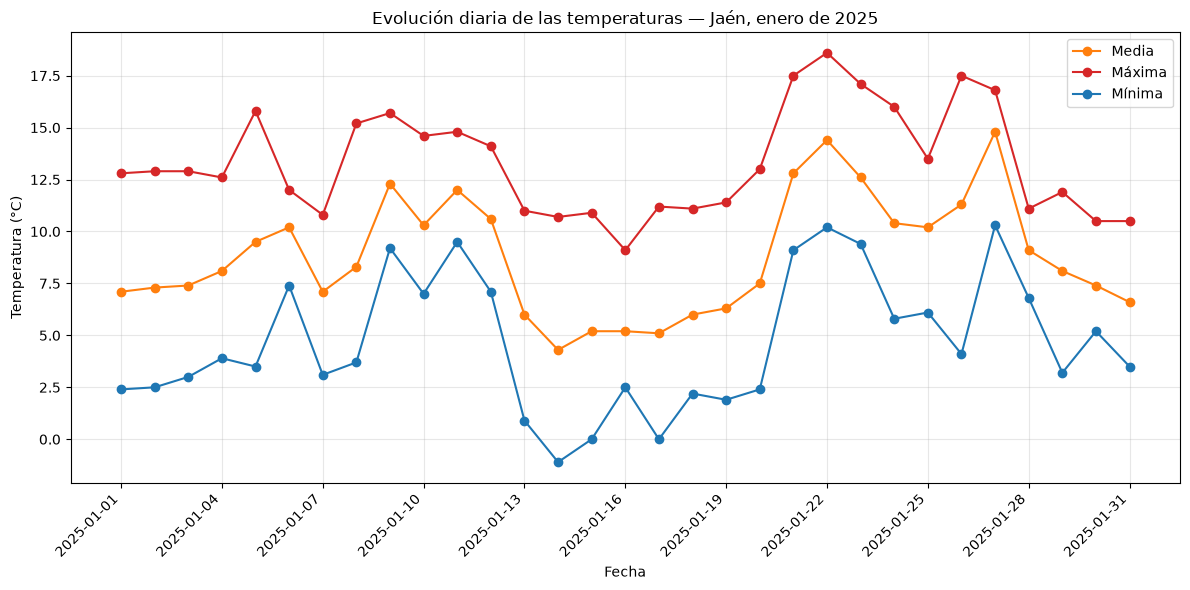

Guardado en: graficos\09_evolucion_temperaturas.png


In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(fechas, temperaturas_medias, color="tab:orange", marker="o", label="Media")
ax.plot(fechas, temperaturas_maximas, color="tab:red", marker="o", label="Máxima")
ax.plot(fechas, temperaturas_minimas, color="tab:blue", marker="o", label="Mínima")

ax.set_title("Evolución diaria de las temperaturas — Jaén, enero de 2025")
ax.set_xlabel("Fecha")
ax.set_ylabel("Temperatura (°C)")
ax.set_xticks(range(0, len(fechas), 3), fechas[::3], rotation=45, ha="right")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

ruta_lineas = directorio_salida / "09_evolucion_temperaturas.png"
fig.savefig(ruta_lineas, dpi=150, bbox_inches="tight")
plt.show()
print("Guardado en:", ruta_lineas)

### 2. Gráfico de barras: comparación semanal

Comparamos las medias semanales de las temperaturas medias, máximas y mínimas. La quinta semana solo contiene los días 29, 30 y 31.

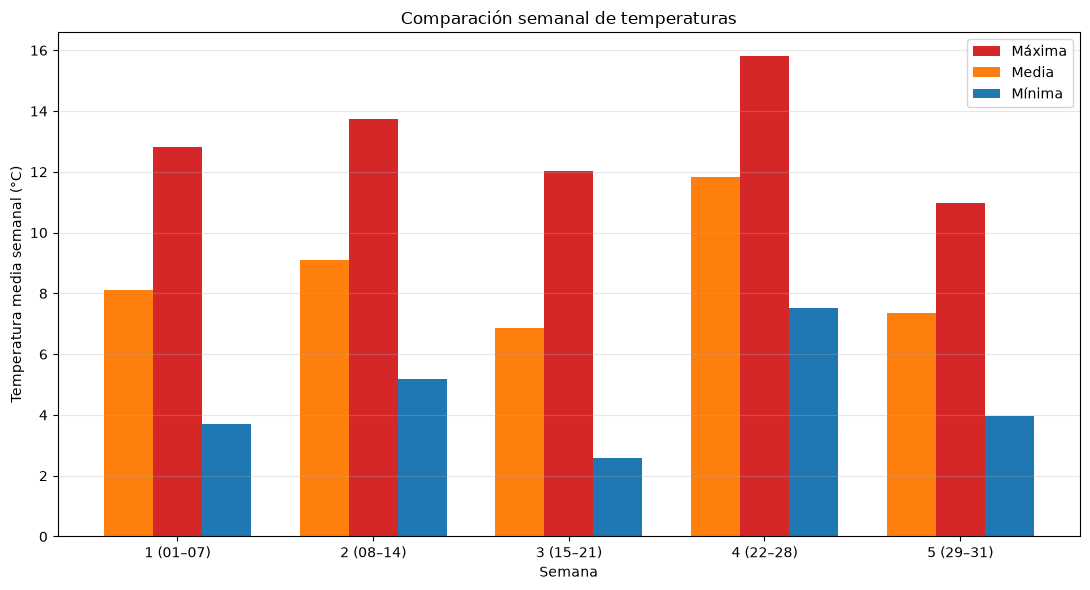

Guardado en: graficos\09_comparacion_semanal.png


In [10]:
def calcular_medias_semanales(valores):
    return [round(np.mean(valores[inicio:inicio + 7]), 2) for inicio in range(0, len(valores), 7)]

medias_semanales = calcular_medias_semanales(temperaturas_medias)
maximas_semanales = calcular_medias_semanales(temperaturas_maximas)
minimas_semanales = calcular_medias_semanales(temperaturas_minimas)

etiquetas_semanas = ["1 (01–07)", "2 (08–14)", "3 (15–21)", "4 (22–28)", "5 (29–31)"]
posiciones = np.arange(len(etiquetas_semanas))
ancho = 0.25

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(posiciones, maximas_semanales, ancho, color="tab:red", label="Máxima")
ax.bar(posiciones - ancho, medias_semanales, ancho, color="tab:orange", label="Media")
ax.bar(posiciones + ancho, minimas_semanales, ancho, color="tab:blue", label="Mínima")

ax.set_title("Comparación semanal de temperaturas")
ax.set_xlabel("Semana")
ax.set_ylabel("Temperatura media semanal (°C)")
ax.set_xticks(posiciones, etiquetas_semanas)
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()

ruta_barras = directorio_salida / "09_comparacion_semanal.png"
fig.savefig(ruta_barras, dpi=150, bbox_inches="tight")
plt.show()
print("Guardado en:", ruta_barras)

### 3. Amplitud térmica diaria

La amplitud térmica es la diferencia entre la máxima y la mínima de cada día. La mayor fue de `13.4 °C` el `2025-01-26`, y la amplitud media fue de `8.67 °C`.

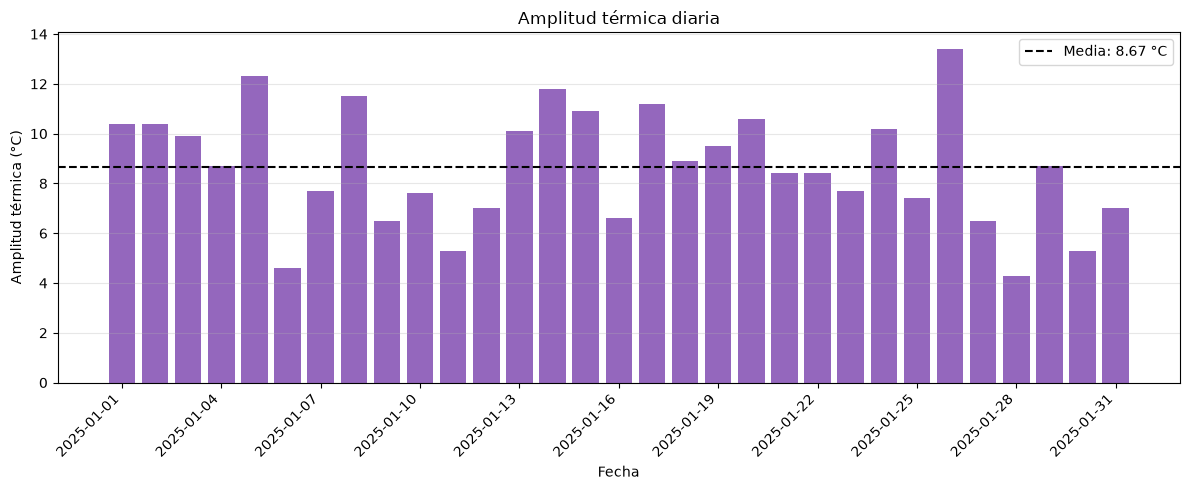

Mayor amplitud: 2025-01-26 -> 13.4 °C
Guardado en: graficos\09_amplitud_termica.png


In [11]:
amplitudes = temperaturas_maximas - temperaturas_minimas
indice_mayor_amplitud = int(np.argmax(amplitudes))

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(fechas, amplitudes, color="tab:purple")
ax.axhline(np.mean(amplitudes), color="black", linestyle="--", label=f"Media: {np.mean(amplitudes):.2f} °C")

ax.set_title("Amplitud térmica diaria")
ax.set_xlabel("Fecha")
ax.set_ylabel("Amplitud térmica (°C)")
ax.set_xticks(range(0, len(fechas), 3), fechas[::3], rotation=45, ha="right")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()

ruta_amplitud = directorio_salida / "09_amplitud_termica.png"
fig.savefig(ruta_amplitud, dpi=150, bbox_inches="tight")
plt.show()

print("Mayor amplitud:", fechas[indice_mayor_amplitud], "->", amplitudes[indice_mayor_amplitud], "°C")
print("Guardado en:", ruta_amplitud)

### 4. Histogramas: distribución de las temperaturas

Con intervalos comunes de `4 °C`, los más frecuentes son:

- Temperaturas medias: de `6 °C` a menos de `10 °C`, con 15 días.
- Temperaturas máximas: de `10 °C` a menos de `14 °C`, con 18 días.
- Temperaturas mínimas: de `2 °C` a menos de `6 °C`, con 15 días.

Las mínimas presentan mayor dispersión que las máximas, mientras que las medias se concentran principalmente entre `6 °C` y `14 °C`.

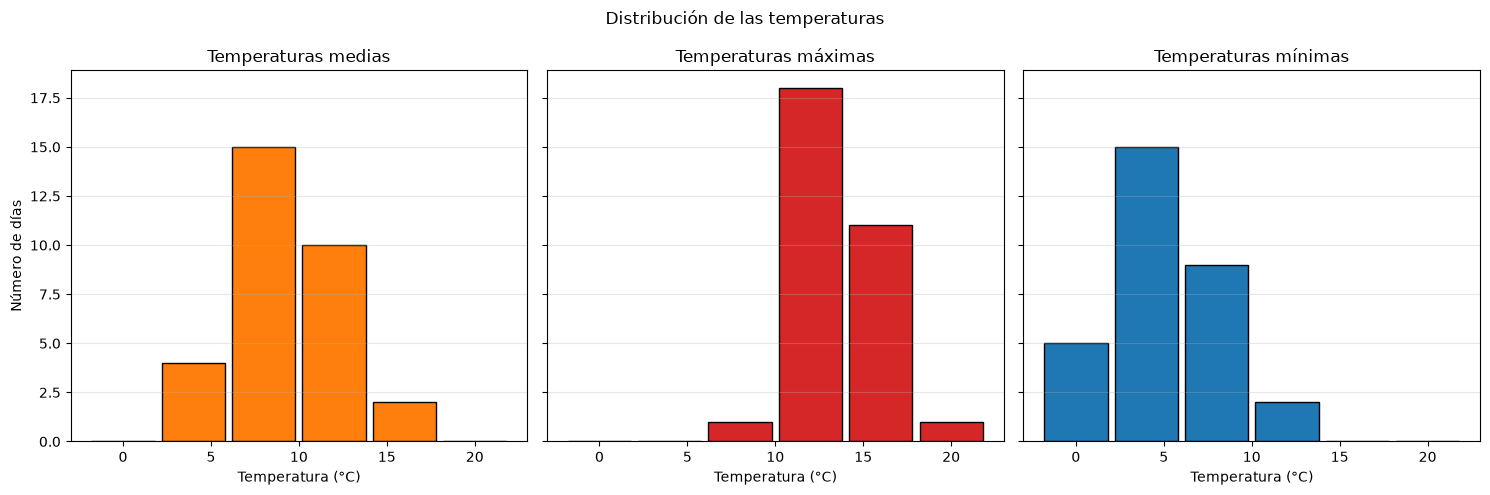

Intervalos más frecuentes: {'Medias': {'desde': np.int64(6), 'hasta': np.int64(10), 'dias': 15}, 'Máximas': {'desde': np.int64(10), 'hasta': np.int64(14), 'dias': 18}, 'Mínimas': {'desde': np.int64(2), 'hasta': np.int64(6), 'dias': 15}}
Guardado en: graficos\09_histogramas_temperaturas.png


In [12]:
bordes = np.array([-2, 2, 6, 10, 14, 18, 22])
series_histograma = [
    ("Medias", temperaturas_medias, "tab:orange"),
    ("Máximas", temperaturas_maximas, "tab:red"),
    ("Mínimas", temperaturas_minimas, "tab:blue"),
]

fig, ejes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
intervalos_frecuentes = {}

for eje, (nombre, valores, color) in zip(ejes, series_histograma):
    conteos, _ = np.histogram(valores, bins=bordes)
    indice_frecuente = int(np.argmax(conteos))
    intervalos_frecuentes[nombre] = {
        "desde": bordes[indice_frecuente],
        "hasta": bordes[indice_frecuente + 1],
        "dias": int(conteos[indice_frecuente]),
    }
    eje.hist(valores, bins=bordes, color=color, edgecolor="black", rwidth=0.9)
    eje.set_title(f"Temperaturas {nombre.lower()}")
    eje.set_xlabel("Temperatura (°C)")
    eje.grid(axis="y", alpha=0.3)

ejes[0].set_ylabel("Número de días")
fig.suptitle("Distribución de las temperaturas")
fig.tight_layout()

ruta_histogramas = directorio_salida / "09_histogramas_temperaturas.png"
fig.savefig(ruta_histogramas, dpi=150, bbox_inches="tight")
plt.show()

print("Intervalos más frecuentes:", intervalos_frecuentes)
print("Guardado en:", ruta_histogramas)

### 5. Diagrama de dispersión: relación entre mínimas y máximas

La correlación es aproximadamente `0.70`, por lo que existe una relación positiva: los días con mínimas más altas suelen tener máximas más altas. Sin embargo, el coeficiente de determinación es aproximadamente `0.49`; la mínima explica solo parte de la variación de la máxima. Por ello podría realizarse una estimación aproximada, pero no una predicción precisa usando únicamente la mínima.

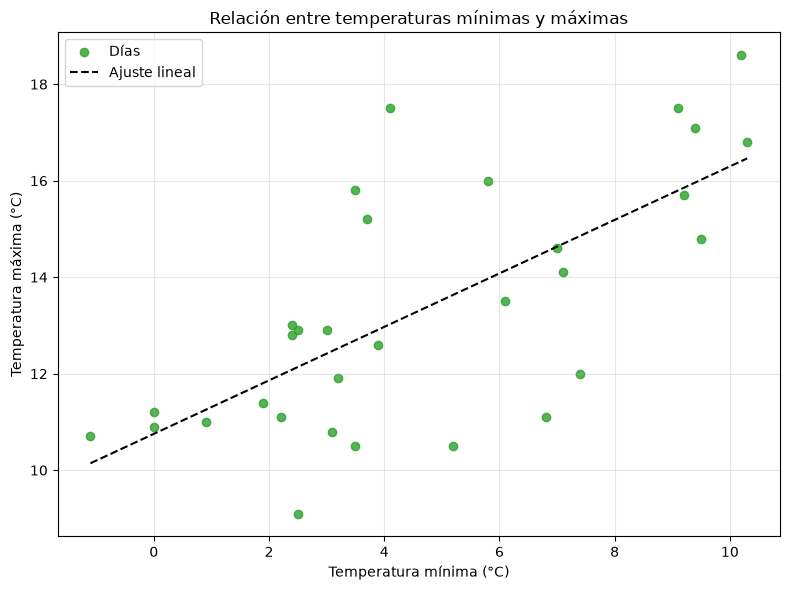

Correlación: 0.7
Coeficiente de determinación: 0.49
Guardado en: graficos\09_dispersion_minimas_maximas.png


In [13]:
correlacion = np.corrcoef(temperaturas_minimas, temperaturas_maximas)[0, 1]
pendiente, intercepto = np.polyfit(temperaturas_minimas, temperaturas_maximas, 1)
coeficiente_determinacion = correlacion ** 2
orden = np.argsort(temperaturas_minimas)
recta_ajuste = pendiente * temperaturas_minimas[orden] + intercepto

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(temperaturas_minimas, temperaturas_maximas, color="tab:green", alpha=0.8, label="Días")
ax.plot(temperaturas_minimas[orden], recta_ajuste, color="black", linestyle="--", label="Ajuste lineal")

ax.set_title("Relación entre temperaturas mínimas y máximas")
ax.set_xlabel("Temperatura mínima (°C)")
ax.set_ylabel("Temperatura máxima (°C)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

ruta_dispersion = directorio_salida / "09_dispersion_minimas_maximas.png"
fig.savefig(ruta_dispersion, dpi=150, bbox_inches="tight")
plt.show()

print("Correlación:", round(correlacion, 2))
print("Coeficiente de determinación:", round(coeficiente_determinacion, 2))
print("Guardado en:", ruta_dispersion)

## Conclusiones

El **gráfico de líneas** es el más útil para estudiar la evolución temporal porque conserva el orden de las fechas y permite observar simultáneamente las tres series.

1. Las temperaturas descendieron a mediados de mes y aumentaron con claridad entre el 20 y el 27 de enero; después volvieron a bajar.
2. La cuarta semana fue la más cálida en las tres series. La amplitud térmica más alta se produjo el 26 de enero y alcanzó `13.4 °C`.
3. Las mínimas y máximas presentan una relación positiva moderadamente fuerte (`r ≈ 0.70`), pero la dispersión indica que la mínima no basta para predecir con precisión la máxima.